**Results from `IIVV-GPU-all.py` are required**

In [1]:
# combine IIVV-analysis results
from glob import glob

import pandas as pd

csv_files = glob(f"results/IIVV-analysis_*_gpu.csv")
print(csv_files)

if len(csv_files) == 3:
    df_list = [pd.read_csv(file) for file in csv_files]
    combined_df = pd.concat(df_list, ignore_index=True)

    print(len(combined_df))
    combined_df
    combined_df.to_csv(f"results/IIVV-analysis.csv", index=False)
else:
    print("One or more IIVV-analysis_*.csv files are missing.")

['results/IIVV-analysis_healthy_vs_cancer_gpu.csv', 'results/IIVV-analysis_hr_vs_lr_gpu.csv', 'results/IIVV-analysis_MC_gpu.csv']
1800


## Create plots

In [2]:
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
df = pd.read_csv(f"results/IIVV-analysis.csv")
df

,Task,Fold,IIVV,rs,auc,n_params
0,healthy_vs_cancer,1,Long a+,0,0.730769,496
1,healthy_vs_cancer,2,Long a+,0,0.879552,496
2,healthy_vs_cancer,3,Long a+,0,0.934256,496
3,healthy_vs_cancer,4,Long a+,0,0.898246,496
4,healthy_vs_cancer,5,Long a+,0,0.861592,496
...,...,...,...,...,...,...
1795,MC,1,Opp. far,9,0.764133,8184
1796,MC,2,Opp. far,9,0.754889,8184
1797,MC,3,Opp. far,9,0.637694,8184
1798,MC,4,Opp. far,9,0.732011,8184


In [24]:
# select specific task
class_task = "healthy_vs_cancer"
class_task = "hr_vs_lr"
class_task = "MC"

df_task = df.loc[df["Task"] == class_task]

In [25]:
# mean over rs
df_mean = df_task.groupby(["Task", "IIVV", "Fold"], as_index=False)["auc"].mean()
# create pivot table
df_pivot = df_mean.pivot(index="IIVV", columns="Fold", values="auc")

In [26]:
df_pivot

Fold,1,2,3,4,5
IIVV,,,,,
Adj. close,0.738553,0.754077,0.765355,0.719292,0.741410
Adj. far,0.749568,0.765757,0.752500,0.746008,0.763994
Long a+,0.739545,0.764811,0.754134,0.722431,0.761461
Long a+ ext.,0.744429,0.770798,0.749569,0.724603,0.757305
Med. a+ ext.,0.749510,0.767485,0.756605,0.738000,0.754385
Med. adj.,0.744599,0.755479,0.752661,0.730516,0.754276
Opp. close,0.741057,0.770027,0.764757,0.727898,0.753562
Opp. far,0.740709,0.766406,0.749042,0.743767,0.754882
Opp. medium,0.748926,0.771180,0.745431,0.758663,0.761726


In [27]:
df_mean = df_pivot.mean(axis=1)
df_sorted = df_mean.sort_values(ascending=False)
print(df_sorted)

IIVV
Opp. medium     0.757185
Adj. far        0.755565
Skip1 medium    0.754144
Skip1 far       0.753313
Med. a+ ext.    0.753197
Opp. close      0.751460
Opp. far        0.750961
Long a+ ext.    0.749341
Long a+         0.748476
Med. adj.       0.747506
Adj. close      0.743737
Skip1 close     0.740442
dtype: float64


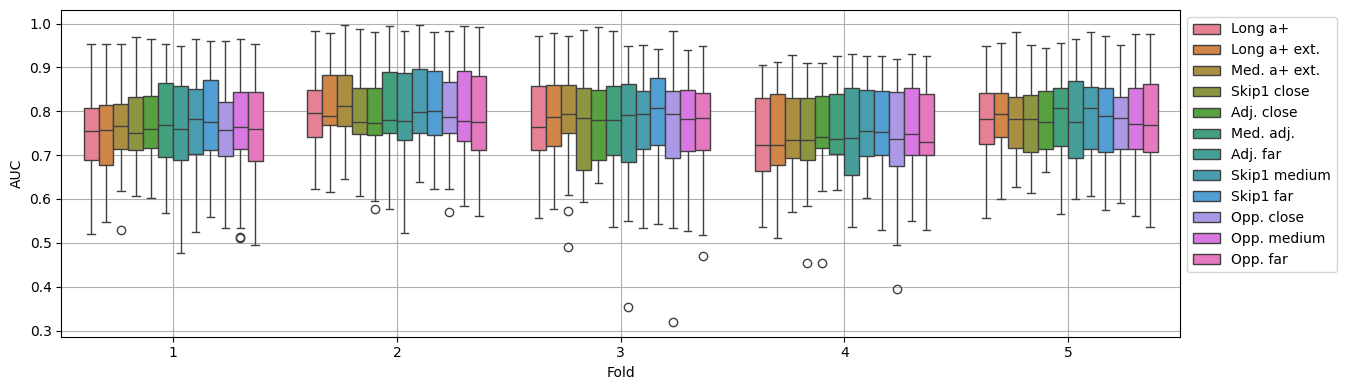

In [9]:
plt.figure(figsize=(12, 4))
sns.boxplot(x="Fold", y="auc", hue="IIVV", data=df)
plt.grid()
plt.ylabel("AUC")
plt.tight_layout()
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

## Take heuristically selected IIVV pattern

In [3]:
# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}

NameError: name 'class_task' is not defined

In [ ]:
# add baseline pattern
Mask_sel["All"] = "all"

In [ ]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

In [ ]:
results = []
numXparams = []
for Mname, Msel in Mask_sel.items():
    mask.IIVV_mask(Msel, plot=False)
    # apply mask
    X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(7):
        print("Trial:", trial, "\n\t", Mname)
        avg_roc_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})

df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/IIVV-analysis_{class_task}_sm.csv", index=False)
df_params.to_csv(f"results/IIVV-analysis_{class_task}_params_sm.csv", index=False)

In [ ]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}_sm.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params_sm.csv")

In [ ]:
Mask_sel.keys()

In [ ]:
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

fig = plt.figure(figsize=(9.4, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
# defined order
# order = [
#    "Skip1 medium",
#    "Skip1 far",
#    "Opp. medium",
#    "Long a+",
#    "All",
# ]
order = Mask_sel.keys()
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Mask"],
        markersize=8,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.set_xscale("log")
# ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

ax1.legend(title="IIVV selection", framealpha=0.4)
plt.savefig(f"results/IIVV_sel_perf_{class_task}_sm.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_plot

___

## Statistical impact of IIVV maskimport numpy as np

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import label_binarize
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.results import Results_data_loading
from tqdm import tqdm

IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

tasks = ["healthy_vs_cancer"]


for class_task in tasks:
    stats = []
    print(class_task)
    X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
        class_task, data_augmentation=False
    )
    classes = np.unique(Y_labels)
    n_classes = len(classes)

    for Msel in Mask_sel.keys():
        if Msel == "All":
            X_tmp = X.reshape(X.shape[0], -1)
        else:
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            X_tmp = X[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
        for rs in tqdm(range(20)):
            m = SVC(probability=True, random_state=0)
            cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
            for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
                X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
                y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
                m.fit(X_train, y_train)
                probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
                if n_classes == 2:
                    roc_auc = roc_auc_score(y_test, probs[:, 1])
                else:
                    # Binarize true labels
                    y_bin = label_binarize(
                        y_test, classes=classes
                    )  # shape (n_samples, n_classes)
                    # Micro-average ROC
                    fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                    roc_auc = auc(fpr, tpr)
                stats.append(
                    {"Task": class_task, "IIVV": Msel, "rs": rs, "auc": roc_auc}
                )

    df_stats = pd.DataFrame(stats)
    df_stats.to_csv(f"results/IIVV-analysis_{class_task}_statistics.csv", index=False)

healthy_vs_cancer

	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}


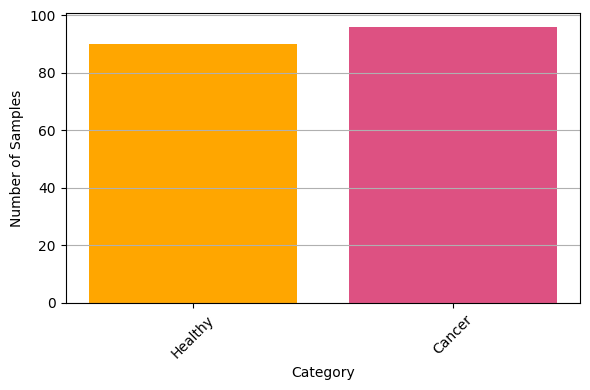


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)
Task 1 Z-threshold: 386


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [2:33:55<00:00, 461.79s/it]


cancer_vs_lr_hr

	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. LR vs. HR

Cancer: 96 entries
High risk: 29 entries
Low risk: 41 entries
Available cases: ['Cancer' 'High risk' 'Low risk']
Coding: -> forward
{'Cancer': [1, 0, 0], 'High risk': [0, 1, 0], 'Low risk': [0, 0, 1]}


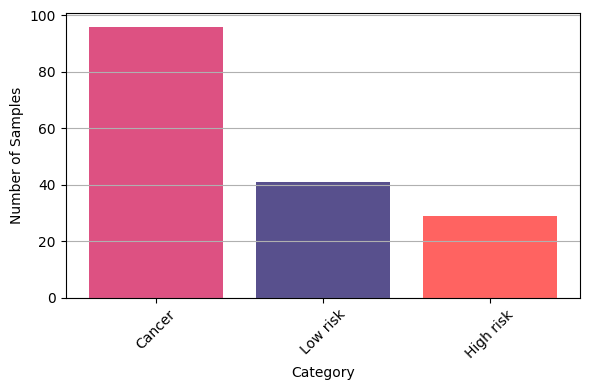


Inverse mapping: {(1, 0, 0): 'Cancer', (0, 1, 0): 'High risk', (0, 0, 1): 'Low risk'}
(166, 31, 7728) (166, 3) (166,)
Task 2 Z-threshold: 314


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [1:59:24<00:00, 358.24s/it]


MC

	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

MC

Healthy: 90 entries
Cancer: 96 entries
High-grade dysplasia: 29 entries
Non-malignant: 41 entries
Available cases: ['Cancer' 'Healthy' 'High-grade dysplasia' 'Non-malignant']
Coding: -> forward
{'Cancer': [1, 0, 0, 0], 'Healthy': [0, 1, 0, 0], 'High-grade dysplasia': [0, 0, 1, 0], 'Non-malignant': [0, 0, 0, 1]}


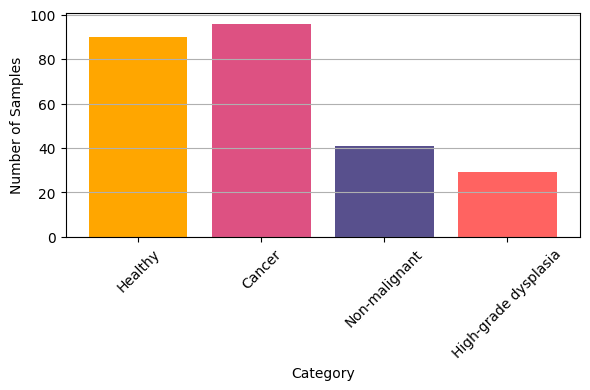


Inverse mapping: {(1, 0, 0, 0): 'Cancer', (0, 1, 0, 0): 'Healthy', (0, 0, 1, 0): 'High-grade dysplasia', (0, 0, 0, 1): 'Non-malignant'}
(256, 31, 7728) (256, 4) (256,)
Task 3 Z-threshold: 592


 25%|██████████████████████████                                                                              | 5/20 [1:10:47<4:00:12, 960.82s/it]

In [ ]:
# Z threshold results
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox.results import Results_data_loading
from tqdm import tqdm
from sklearn.preprocessing import label_binarize
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel

IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
tasks = ["healthy_vs_cancer", "hr_vs_lr", "MC"]
# Z-thresholding selection


for class_task in tasks:
    stats = []
    print(class_task)
    X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
        class_task, data_augmentation=False
    )
    classes = np.unique(Y_labels)
    n_classes = len(classes)

    # load in average impedances
    avg_Z_fp = np.load("source/Avg_Zs.npy")

    if class_task == "healthy_vs_cancer":
        print("Task 1 Z-threshold: 424")
        z_thresh = 424
    elif class_task == "hr_vs_lr":
        print("Task 2 Z-threshold: 105")
        z_thresh = 105
    elif class_task == "MC":
        print("Task 3 Z-threshold: 212")
        z_thresh = 212

    Msel = f"z_threshold: {z_thresh}"

    # Select columns/patterns for this threshold
    above_threshold = avg_Z_fp[0, :] <= z_thresh
    X_tmp = X[:, :, above_threshold]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
            if n_classes == 2:
                roc_auc = roc_auc_score(y_test, probs[:, 1])
            else:
                # Binarize true labels
                y_bin = label_binarize(
                    y_test, classes=classes
                )  # shape (n_samples, n_classes)
                # Micro-average ROC
                fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                roc_auc = auc(fpr, tpr)

            stats.append({"Task": class_task, "IIVV": Msel, "rs": rs, "auc": roc_auc})

    df_stats = pd.DataFrame(stats)
    df_stats.to_csv(
        f"results/IIVV-analysis_{class_task}_z_threshold_statistics.csv", index=False
    )

## Save top $\mathbf{f}_\mathrm{T}$ frequencies